In [1]:
%load_ext autoreload
%autoreload 2
import ast, re
import numpy as np
import pandas as pd
from sklearn.model_selection import cross_validate
from src.config import *
from src.utils import *
from src.experiments import run_experiment, show, augmented_cv, build_models, CV, MULTI_SCORING

base = pd.read_csv(MULTI_FEATURES_TRAIN_CSV)
base_aug = pd.read_csv(MULTI_FEATURES_AUG_CSV)
train = base.merge(pd.read_csv(MULTI_REGIONAL_TRAIN_CSV).drop(columns="label"), on="filename")
aug = base_aug.merge(pd.read_csv(MULTI_REGIONAL_AUG_CSV).drop(columns="label"), on="filename")
assert (train["filename"] == base["filename"]).all() and (aug["filename"] == base_aug["filename"]).all()

base_cols = [c for c in base.columns if c not in ("filename", "label")]
f1_cols = base_cols + [c for c in train.columns if c.startswith("reg_")]

y = train["label"].values
y_all = np.concatenate([y, aug["label"].values])
splits = augmented_cv(train["filename"], aug["source_filename"], y_all)   # same test folds as CV

def data_for(cols, augmented):
    """X, y and folds for one feature set, with or without the augmented scc copies."""
    if augmented:
        return np.vstack([train[cols].values, aug[cols].values]), y_all, splits
    return train[cols].values, y, CV

def parse(p):
    """Params from the CSV (text with np.float64(...)) or already a dict."""
    return ast.literal_eval(re.sub(r"np\.float64\(([^)]*)\)", r"\1", p)) if isinstance(p, str) else p

print(len(base_cols), "base |", len(f1_cols), "base + regional |", len(train), "originals |", len(aug), "augmented")

230 base | 442 base + regional | 5082 originals | 1504 augmented


seed: 235


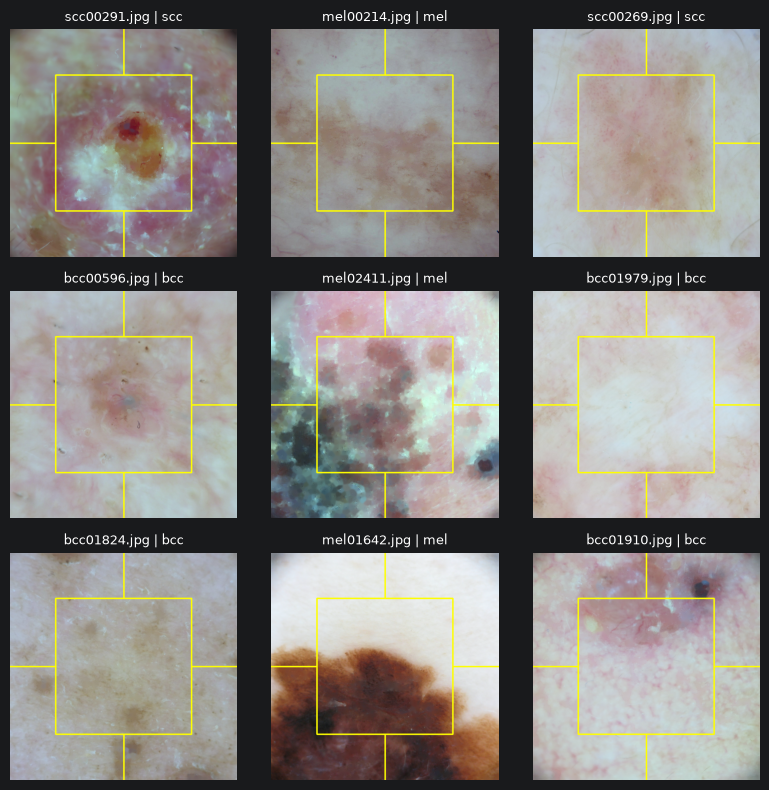

In [2]:
from src.feature_extraction import draw_regions

s = random_sample(train)
show_grid([draw_regions(load_preprocessed(r.filename, r.label, MULTI_PREPROC_TRAIN_DIR, MULTI_CLASS_FOLDERS))
           for r in s.itertuples()], [f"{r.filename} | {MULTI_CLASS_NAMES[r.label]}" for r in s.itertuples()])

In [3]:
# new name: (old name, augmented, weighted)
EXPERIMENTS = {
    "MF0 no handling":            ("M0 no handling", False, False),
    "MF1 class weights":          ("M1 class weights", False, True),
    "MF2 augmentation":           ("M2 augmentation", True, False),
    "MF3 augmentation + weights": ("M3 augmentation + weights", True, True),
}

tables, fitted = [], {}
for name, (_, augmented, weighted) in EXPERIMENTS.items():
    X_, y_, cv_ = data_for(f1_cols, augmented)
    table, fit = run_experiment(name, X_, y_, task="multiclass", weighted=weighted, cv=cv_)
    tables.append(table)
    fitted.update({(name, m): f for m, f in fit.items()})
    pd.concat(tables, ignore_index=True).to_csv(RESULTS_DIR / "multi_exp_regional.csv", index=False)

new = pd.concat(tables, ignore_index=True)
show(new.sort_values("kappa", ascending=False), task="multiclass")

[MF0 no handling] LogReg: kappa = 0.669
[MF0 no handling] Random Forest: kappa = 0.663
[MF0 no handling] HistGradBoost: kappa = 0.717
[MF0 no handling] SVM (RBF): kappa = 0.754
[MF0 no handling] XGBoost: kappa = 0.723
[MF0 no handling] CatBoost: kappa = 0.702
[MF1 class weights] LogReg: kappa = 0.669
[MF1 class weights] Random Forest: kappa = 0.671
[MF1 class weights] HistGradBoost: kappa = 0.720
[MF1 class weights] SVM (RBF): kappa = 0.744
[MF1 class weights] XGBoost: kappa = 0.724
[MF1 class weights] CatBoost: kappa = 0.710
[MF2 augmentation] LogReg: kappa = 0.638
[MF2 augmentation] Random Forest: kappa = 0.678
[MF2 augmentation] HistGradBoost: kappa = 0.715
[MF2 augmentation] SVM (RBF): kappa = 0.740
[MF2 augmentation] XGBoost: kappa = 0.726
[MF2 augmentation] CatBoost: kappa = 0.704
[MF3 augmentation + weights] LogReg: kappa = 0.640
[MF3 augmentation + weights] Random Forest: kappa = 0.677
[MF3 augmentation + weights] HistGradBoost: kappa = 0.720
[MF3 augmentation + weights] SVM (R

,experiment,model,kappa,recall_mel,recall_bcc,recall_scc,f1_macro
3,MF0 no handling,SVM (RBF),0.754 ± 0.011,0.921 ± 0.010,0.876 ± 0.020,0.420 ± 0.040,0.764 ± 0.012
9,MF1 class weights,SVM (RBF),0.744 ± 0.009,0.913 ± 0.010,0.856 ± 0.018,0.481 ± 0.047,0.762 ± 0.011
15,MF2 augmentation,SVM (RBF),0.740 ± 0.017,0.916 ± 0.016,0.851 ± 0.019,0.463 ± 0.038,0.754 ± 0.014
21,MF3 augmentation + weights,SVM (RBF),0.739 ± 0.010,0.908 ± 0.013,0.856 ± 0.014,0.476 ± 0.030,0.756 ± 0.011
16,MF2 augmentation,XGBoost,0.726 ± 0.017,0.910 ± 0.016,0.845 ± 0.027,0.428 ± 0.019,0.737 ± 0.017
10,MF1 class weights,XGBoost,0.724 ± 0.017,0.918 ± 0.012,0.883 ± 0.019,0.205 ± 0.044,0.689 ± 0.023
22,MF3 augmentation + weights,XGBoost,0.724 ± 0.025,0.910 ± 0.015,0.842 ± 0.028,0.423 ± 0.046,0.735 ± 0.025
4,MF0 no handling,XGBoost,0.723 ± 0.019,0.920 ± 0.012,0.879 ± 0.024,0.210 ± 0.023,0.691 ± 0.015
8,MF1 class weights,HistGradBoost,0.720 ± 0.021,0.914 ± 0.016,0.882 ± 0.022,0.213 ± 0.040,0.691 ± 0.023
20,MF3 augmentation + weights,HistGradBoost,0.720 ± 0.019,0.906 ± 0.021,0.849 ± 0.030,0.391 ± 0.034,0.725 ± 0.022


In [4]:
old = pd.concat([pd.read_csv(RESULTS_DIR / "multi_exp_baseline.csv"),
                 pd.read_csv(RESULTS_DIR / "multi_exp_augmentation.csv")], ignore_index=True)

folds = []
for new_name, (old_name, augmented, weighted) in EXPERIMENTS.items():
    for name, table, cols in [(old_name, old, base_cols), (new_name, new, f1_cols)]:
        best = table[table["experiment"] == name].nlargest(1, "kappa").iloc[0]
        model = build_models(weighted=weighted)[best["model"]].set_params(**parse(best["params"]))
        X_, y_, cv_ = data_for(cols, augmented)
        s = cross_validate(model, X_, y_, cv=cv_, scoring=MULTI_SCORING, n_jobs=-2)
        folds.append(pd.DataFrame({m: s[f"test_{m}"] for m in MULTI_SCORING})
                     .assign(experiment=name, model=best["model"], fold=range(5)))
folds = pd.concat(folds, ignore_index=True)
folds.to_csv(RESULTS_DIR / "multi_exp_regional_folds.csv", index=False)

k = folds.pivot(index="fold", columns="experiment", values="kappa")
scc = folds.pivot(index="fold", columns="experiment", values="recall_scc")
rows = []
for new_name, (old_name, *_) in EXPERIMENTS.items():
    d = k[new_name] - k[old_name]
    rows.append({"experiment": new_name, "kappa base": k[old_name].mean(), "kappa + regional": k[new_name].mean(),
                 "gain": d.mean(), "std": d.std(), "folds won": (d > 0).sum(),
                 "scc recall base": scc[old_name].mean(), "scc recall + regional": scc[new_name].mean()})
pd.DataFrame(rows).round(3)

,experiment,kappa base,kappa + regional,gain,std,folds won,scc recall base,scc recall + regional
0,MF0 no handling,0.720,0.754,0.034,0.022,5,0.367,0.420
1,MF1 class weights,0.717,0.744,0.027,0.025,4,0.327,0.481
2,MF2 augmentation,0.704,0.740,0.037,0.022,5,0.399,0.463
3,MF3 augmentation + weights,0.705,0.739,0.034,0.018,5,0.420,0.476


### Let's try now two ensembles: Stacking VS Soft voting, with the MF0 settings (base + regional features with no unbalance handling methods)

In [5]:
import time
import joblib
import matplotlib.pyplot as plt
from sklearn.base import clone
from src.experiments import build_ensembles, evaluate

BASE = ["SVM (RBF)", "XGBoost", "HistGradBoost", "CatBoost"]
mf0 = pd.read_csv(RESULTS_DIR / "multi_exp_regional.csv").query("experiment == 'MF0 no handling'").set_index("model")

all_models = build_models()
base_models = {m: clone(all_models[m]).set_params(**parse(mf0.loc[m, "params"])) for m in BASE}
X_f1 = train[f1_cols].values
{m: parse(mf0.loc[m, "params"]) for m in BASE}

{'SVM (RBF)': {'clf__C': 11.290133559092672,
  'clf__gamma': 0.0020914981329035616},
 'XGBoost': {'clf__colsample_bytree': 0.6247240713084175,
  'clf__learning_rate': 0.18214744423753768,
  'clf__max_depth': 5,
  'clf__min_child_weight': 8,
  'clf__n_estimators': 388,
  'clf__subsample': 0.8387400631785948},
 'HistGradBoost': {},
 'CatBoost': {'clf__depth': 7,
  'clf__iterations': 587,
  'clf__l2_leaf_reg': 2.0497980520950176,
  'clf__learning_rate': 0.08046552389871331}}

In [6]:
ens_folds = []
for name, ens in build_ensembles(base_models).items():
    start = time.perf_counter()
    s = cross_validate(ens, X_f1, y, cv=CV, scoring=MULTI_SCORING, n_jobs=5)    # one fold per core
    print(f"{name}: {(time.perf_counter() - start) / 60:.0f} min")
    ens_folds.append(pd.DataFrame({m: s[f"test_{m}"] for m in MULTI_SCORING})
                     .assign(experiment="MF0 ensembles", model=name, fold=range(5)))
ens_folds = pd.concat(ens_folds, ignore_index=True)
ens_folds.to_csv(RESULTS_DIR / "multi_exp_regional_ensembles_folds.csv", index=False)

Soft voting: 14 min
Stacking (LogReg): 77 min


In [7]:
metrics = list(MULTI_SCORING)
svm_folds = (pd.read_csv(RESULTS_DIR / "multi_exp_regional_folds.csv")
             .query("experiment == 'MF0 no handling'").sort_values("fold"))
allf = pd.concat([svm_folds, ens_folds], ignore_index=True)
display(allf.groupby("model", sort=False)[metrics].mean().round(3))

for name, g in ens_folds.groupby("model", sort=False):
    d = g.sort_values("fold")["kappa"].values - svm_folds["kappa"].values
    print(f"{name} - SVM: kappa {d.mean():+.3f} ± {d.std(ddof=1):.3f}  (folds won: {(d > 0).sum()}/5)")

,kappa,recall_mel,recall_bcc,recall_scc,f1_macro
model,,,,,
SVM (RBF),0.754,0.921,0.876,0.420,0.764
Soft voting,0.733,0.925,0.891,0.189,0.688
Stacking (LogReg),0.745,0.921,0.878,0.348,0.742


Soft voting - SVM: kappa -0.021 ± 0.019  (folds won: 1/5)
Stacking (LogReg) - SVM: kappa -0.010 ± 0.013  (folds won: 1/5)


### Train the best model and evaluate it

In [8]:
CHOICE = "SVM (RBF)"          # "Soft voting", "Stacking (LogReg)" or "SVM (RBF)", decided from E3

final = clone(base_models[CHOICE]) if CHOICE == "SVM (RBF)" else build_ensembles(base_models)[CHOICE]
if CHOICE != "SVM (RBF)":
    final.set_params(n_jobs=4)        # base models train in parallel
start = time.perf_counter()
final.fit(X_f1, y)
print(f"{(time.perf_counter() - start) / 60:.0f} min")
joblib.dump({"model": final, "model_name": CHOICE, "features": f1_cols, "class_names": MULTI_CLASS_NAMES},
            MODELS_DIR / "multi_final.joblib")

0 min


['C:\\Users\\ferra\\MIC\\2n_any_UdG\\CADx\\Project\\Project-1-CAD\\models\\multi_final.joblib']

,kappa,recall_mel,recall_bcc,recall_scc,f1_macro
CV (train),0.754,0.921,0.876,0.42,0.764
validation,0.779,0.923,0.892,0.50,0.799


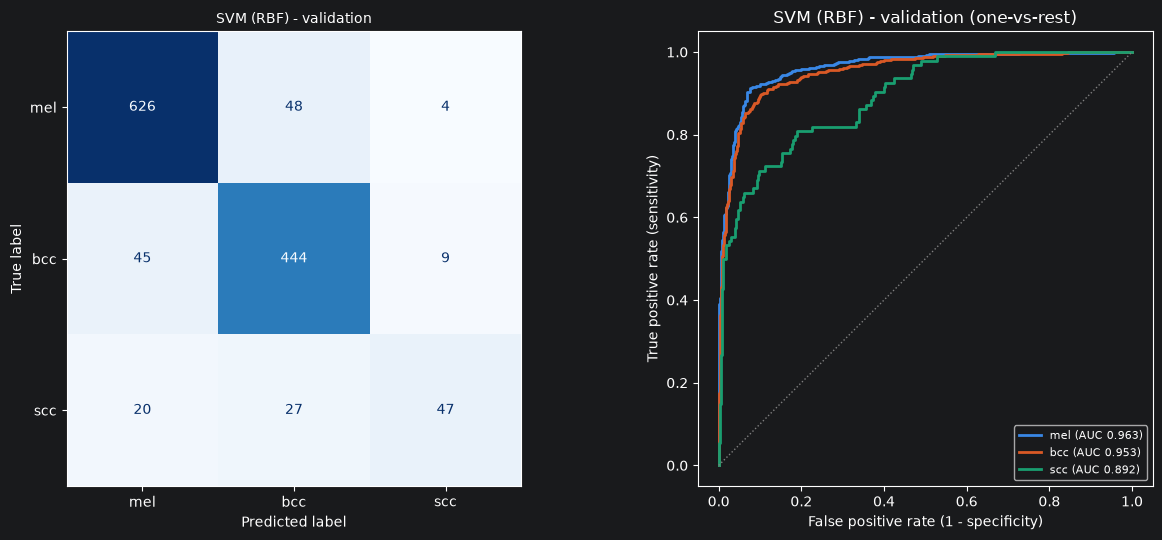

In [9]:
val = pd.read_csv(MULTI_FEATURES_VAL_CSV).merge(
    pd.read_csv(MULTI_REGIONAL_VAL_CSV).drop(columns="label"), on="filename")
X_val, y_val = val[f1_cols].values, val["label"].values

res = pd.DataFrame({"CV (train)": allf[allf["model"] == CHOICE][metrics].mean(),
                    "validation": pd.Series(evaluate(final, X_val, y_val, task="multiclass"))}).T.round(3)
res.to_csv(RESULTS_DIR / "final_multiclass_validation.csv")
display(res)

scores = final.predict_proba(X_val) if hasattr(final, "predict_proba") else final.decision_function(X_val)
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
plot_confusion(axes[0], y_val, final.predict(X_val), f"{CHOICE} - validation", class_names=MULTI_CLASS_NAMES.values())
for label, name in MULTI_CLASS_NAMES.items():
    plot_roc(axes[1], (y_val == label).astype(int), scores[:, label], name, MULTI_CLASS_COLORS[label])
finish_roc(axes[1], f"{CHOICE} - validation (one-vs-rest)")
plt.tight_layout()
plt.show()